# Parameter extraction (ε, β₀, χ)

Fit the closed-form DRAPE model to data and extract:

- **ε**  — over-rotation angle
- **β₀** — optimal DRAG coefficient
- **χ**  — proportionality constant between β-deviation and phase δ

Two stages: **linear** (small-δ approximation, gives initial guesses) then **non-linear blackbox** (full closed form, refined).

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, differential_evolution
import drape_lib as dl

%matplotlib inline
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

## Load the chosen DRAPE scheme

In [2]:
drape_data = np.load(dl.DATA_DIR + 'simulated/drape/0.2512/drape_sim_500pts_-2.0_0.1_0.2512_k1to11_noisy.npz')

x = dl.to_physical(drape_data['beta_range'])  # physical units
y = drape_data['drape_pops']
y_fit = drape_data['y_fit']

ks = np.arange(1, 12)

print(drape_data)
print(x.shape, y.shape, y_fit.shape, len(ks))

NpzFile './data/simulated/drape/0.2512/drape_sim_500pts_-2.0_0.1_0.2512_k1to11_noisy.npz' with keys: beta_range, drape_pops, y_fit
(500,) (11, 500, 4) (11, 500, 4) 11


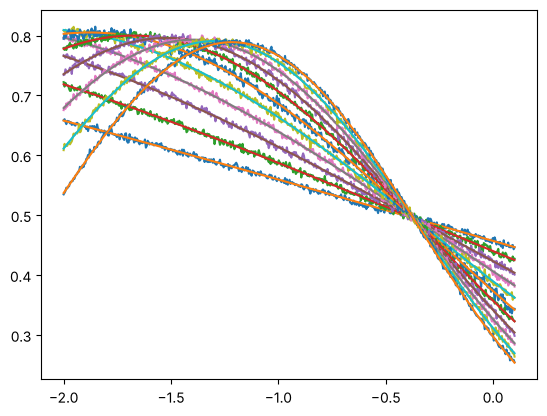

In [3]:
fig, ax = plt.subplots()
for i, k in enumerate(ks):
    ax.plot(x, y[i][:, 2], label=f'k={k}')
    ax.plot(x, y_fit[i][:, 2])

## Stage 1 — Linear fit (small δ)

Two-step linear regression: fit `f = M_k·β + C_k` for each k, then fit `M_k = A·k + B` and `C_k = β₀·M_k + cos²(ε)/2`.

In [4]:
# Window of the sweep used for the fits: the indices around the crossing point of this file
# (beta in [-0.49, -0.26] in physical units; the sweep is stored in normalized units, see drape_lib).
linear_start, linear_stop = 360, 415
betas   = x[linear_start:linear_stop]
f_data  = y[:, linear_start:linear_stop, 2].T   # |2> pop, shape (n_beta, n_k)

# --- Step 1: per-k linear fits ---
mk = np.empty_like(ks, dtype=float)
ck = np.empty_like(ks, dtype=float)
for i, k in enumerate(ks):
    popt, _ = curve_fit(lambda b, m, c: m*b + c, betas, f_data[:, i])
    mk[i], ck[i] = popt

# --- Step 2: M_k vs k → A, B → eps0, xi ---
(A, B), _ = curve_fit(lambda k_, a, b: a*k_ + b, ks, mk)
sin_eps0_guess = (1 - A/B) / 2
eps0_guess     = np.arcsin(sin_eps0_guess)
xi_guess       = B / np.cos(eps0_guess)**2

# --- Step 3: C_k vs M_k → beta0 ---
(neg_beta0, _), _ = curve_fit(
    lambda m_, s, i_: s*m_ + i_, mk, ck)
beta0_guess = -neg_beta0
popt_lin0 = (eps0_guess, xi_guess, beta0_guess )
print(f'Linear-stage estimates: eps0={eps0_guess:.4f}, '
      f'beta0={beta0_guess:.4f}, xi={xi_guess:.4f}')

Linear-stage estimates: eps0=0.1003, beta0=-0.3715, xi=-0.0576


### Linear-stage refinement (global non-linear LS on the same model)

In [5]:
def linear_model(vars, eps0, xi, beta0):
    beta, k    = vars
    cos_eps2   = np.cos(eps0)**2
    return (cos_eps2/2) * (1 + 2*xi*(beta - beta0)*(1 + k*(1 - 2*np.sin(eps0))))

k_mesh, beta_mesh = np.meshgrid(ks, betas)
x_data = np.vstack((beta_mesh.ravel(), k_mesh.ravel()))
y_data = f_data.ravel()

popt_lin, _ = curve_fit(linear_model, x_data, y_data,
                        p0=[eps0_guess, xi_guess, beta0_guess], maxfev=20000)
eps0_lin, xi_lin, beta0_lin = popt_lin

print(f'Linear refined: eps0  = {eps0_lin:>8.5f}  (eye:  0.0977)')
print(f'                xi    = {xi_lin:>8.5f}  (eye: ±0.06)')
print(f'                beta0 = {beta0_lin:>8.5f}  (eye: -0.371355)')


Linear refined: eps0  =  0.09564  (eye:  0.0977)
                xi    = -0.05702  (eye: ±0.06)
                beta0 = -0.37153  (eye: -0.371355)


## Stage 2 — Non-linear blackbox fit (full closed form)

In [6]:
blackbox_start, blackbox_stop = 360, 415
k_start, k_stop = 0, -1
betas_bb          = x[blackbox_start:blackbox_stop]
k_mesh, beta_mesh = np.meshgrid(ks[k_start:k_stop], betas_bb)
f_obs             = y[k_start:k_stop, blackbox_start:blackbox_stop, 2].T

beta_flat = beta_mesh.flatten()
k_flat    = k_mesh.flatten()
f_flat    = f_obs.flatten()

# dl.DRAPE_closed_form_beta returns the |2⟩ pop directly, so the wrapper is
# a one-liner.  np.vectorize handles broadcasting over (beta, k) arrays.
v_model = np.vectorize(dl.DRAPE_closed_form_beta)

def model(vars, eps0, xi, beta0):
    return v_model(vars[0], vars[1], eps0, xi, beta0)

# Sign-agnostic ±5% window around the linear-stage estimate.
def around(x, frac=0.05):
    lo, hi = (1 - frac)*x, (1 + frac)*x
    return (min(lo, hi), max(lo, hi))

bounds = [around(eps0_lin), around(xi_lin), around(beta0_lin)]

# Stage 2a — differential-evolution scout
def objective(p, b, k, f):
    return np.sum((f - model((b, k), *p))**2)

scout = differential_evolution(objective, bounds,
                               args=(beta_flat, k_flat, f_flat),
                               seed=0)

# Stage 2b — curve_fit refinement
popt_bb, pcov = curve_fit(model, (beta_flat, k_flat), f_flat, p0=scout.x, maxfev=20000)
errors        = np.sqrt(np.diag(pcov))

eps0_bb, xi_bb, beta0_bb = popt_bb

In [7]:
print(f'{"param":>8} {"linear":>12} {"blackbox":>12} {"σ (bb)":>12}')
for name, lin, bb, err in zip(
        ['eps0', 'xi', 'beta0'],
        [eps0_lin, xi_lin, beta0_lin],
        [eps0_bb,  xi_bb,  beta0_bb],
        errors):
    print(f'{name:>8} {lin:>12.5f} {bb:>12.5f} {err:>12.2e}')

   param       linear     blackbox       σ (bb)
    eps0      0.09564      0.09552     4.08e-03
      xi     -0.05702     -0.05738     6.65e-04
   beta0     -0.37153     -0.37144     1.16e-03


## Stage 2b — Non-linear blackbox fit with β₀ and χ fixed

Same full closed-form model as above, but **β₀ and χ are no longer fit parameters** — they are frozen at the linear-stage refinement values (`beta0_lin`, `xi_lin`). The only free parameter is **ε** (`eps0`).

In [8]:
# β₀ and χ frozen at the linear-stage refinement values; ε is the only fit parameter.
xi_fixed    = xi_bb
beta0_fixed = beta0_bb

def model_eps(vars, eps0):
    return v_model(vars[0], vars[1], eps0, xi_fixed, beta0_fixed)

# Sign-agnostic ±5% window around the linear-stage eps0 estimate.
bounds_eps = [around(eps0_lin)]

# Stage 2b-i — differential-evolution scout (1-D)
def objective_eps(p, b, k, f):
    return np.sum((f - model_eps((b, k), *p))**2)

scout_eps = differential_evolution(objective_eps, bounds_eps,
                                   args=(beta_flat, k_flat, f_flat),
                                   seed=0)

# Stage 2b-ii — curve_fit refinement (single parameter)
popt_eps, pcov_eps = curve_fit(model_eps, (beta_flat, k_flat), f_flat,
                               p0=scout_eps.x, maxfev=20000)
errors_eps         = np.sqrt(np.diag(pcov_eps))

eps0_bb_fixed = popt_eps[0]
popt_hybrid = np.array([eps0_bb_fixed, xi_fixed, beta0_fixed])

print('eps-only blackbox fit (β₀, χ fixed from linear refinement):')
print(f'    eps0  = {eps0_bb_fixed:>10.5f} ± {errors_eps[0]:.2e}')
print(f'    xi    = {xi_fixed:>10.5f}  (fixed)')
print(f'    beta0 = {beta0_fixed:>10.5f}  (fixed)')

eps-only blackbox fit (β₀, χ fixed from linear refinement):
    eps0  =    0.09552 ± 1.40e-03
    xi    =   -0.05738  (fixed)
    beta0 =   -0.37144  (fixed)


In [9]:
# β₀ and χ are fixed in the hybrid scheme, so they carry no fit error.
hyb     = [eps0_bb_fixed, xi_fixed, beta0_fixed]
hyb_err = [errors_eps[0], None, None]

print(f'{"param":>8} {"linear":>12} {"blackbox":>12} {"\u03c3 (bb)":>12}'
      f' {"hybrid":>12} {"\u03c3 (hyb)":>12}')
for name, lin, bb, err, hb, herr in zip(
        ['eps0', 'xi', 'beta0'],
        [eps0_lin, xi_lin, beta0_lin],
        [eps0_bb,  xi_bb,  beta0_bb],
        errors,
        hyb,
        hyb_err):
    herr_str = f'{herr:.2e}' if herr is not None else 'fixed'
    print(f'{name:>8} {lin:>12.5f} {bb:>12.5f} {err:>12.2e}'
          f' {hb:>12.5f} {herr_str:>12}')

   param       linear     blackbox       σ (bb)       hybrid      σ (hyb)
    eps0      0.09564      0.09552     4.08e-03      0.09552     1.40e-03
      xi     -0.05702     -0.05738     6.65e-04     -0.05738        fixed
   beta0     -0.37153     -0.37144     1.16e-03     -0.37144        fixed


In [10]:
0.04347  

0.04347

## Compare the fitted model to data

Text(0, 0.5, '|2⟩ population')

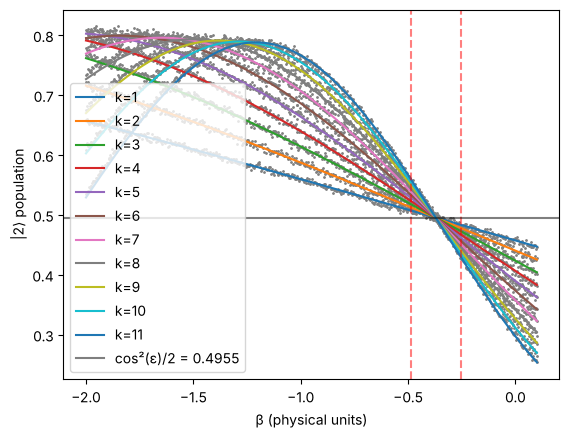

In [11]:
fig, ax = plt.subplots()

for i, k in enumerate(ks):
    ax.scatter(x, y[i, :, 2], color='gray', s=1)
    p2_curve = np.array([dl.DRAPE_closed_form_beta(b, k, *popt_hybrid) for b in x])
    ax.plot(x, p2_curve, label=f'k={k}')

ax.axvline(x[linear_start], color='red', linestyle='--', alpha=0.5)
ax.axvline(x[linear_stop], color='red', linestyle='--', alpha=0.5)
# ax.axvline(x[360], color='blue', linestyle='--', alpha=0.5)
# ax.axvline(x[420], color='blue', linestyle='--', alpha=0.5)
ax.axhline(0.5*np.cos(popt_hybrid[0])**2, color='black', alpha=0.5,
           label=f'cos²(ε)/2 = {0.5*np.cos(popt_hybrid[0])**2:.4f}')
ax.legend()
ax.set_xlabel('β (physical units)')
ax.set_ylabel('|2⟩ population')

In [12]:
def convert_to_delta(beta, xi, beta0):
    return xi * (beta - beta0)

delta_range = convert_to_delta(x, xi_bb, beta0_bb)
delta_degs = np.degrees(delta_range)

Text(0, 0.5, '|2⟩ population')

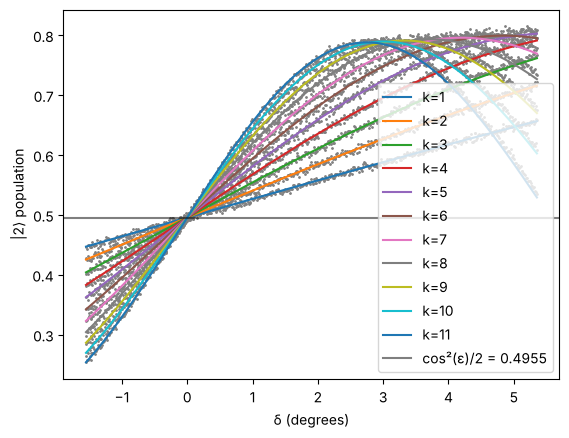

In [13]:
fig, ax = plt.subplots()

for i, k in enumerate(ks):
    ax.scatter(delta_degs, y[i, :, 2], color='gray', s=1)
    p2_curve = np.array([dl.DRAPE_closed_form_beta(b, k, *popt_hybrid) for b in x])
    ax.plot(delta_degs, p2_curve, label=f'k={k}')

# ax.axvline(x[linear_start], color='red', linestyle='--', alpha=0.5)
# ax.axvline(x[linear_stop], color='red', linestyle='--', alpha=0.5)
# ax.axvline(x[blackbox_start], color='blue', linestyle='--', alpha=0.5)
# ax.axvline(x[blackbox_stop], color='blue', linestyle='--', alpha=0.5)
ax.axhline(0.5*np.cos(popt_hybrid[0])**2, color='black', alpha=0.5,
           label=f'cos²(ε)/2 = {0.5*np.cos(popt_hybrid[0])**2:.4f}')
ax.legend()
ax.set_xlabel('δ (degrees)')
ax.set_ylabel('|2⟩ population')

## Export fitted parameters for downstream notebooks

In [14]:
np.savez(dl.DATA_DIR + 'simulated/drape_fit_params.npz',
         eps0=eps0_bb,  beta0=beta0_bb,  xi=xi_bb,
         eps0_linear=eps0_lin, beta0_linear=beta0_lin, xi_linear=xi_lin)

# New estimator

In [15]:
import drape_estimator

In [16]:
drape_estimator.run_on_npz(dl.DATA_DIR + 'simulated/drape/0.2512/drape_sim_500pts_-2.0_0.1_0.2512_k1to11_noisy.npz',
                           beta_to_physical=dl.to_physical)   # the file stores beta in normalized units

eps = 0.09721 +/- 0.00035 rad (5.570 deg),  beta0 = -0.37154 +/- 0.00024,  chi = 0.05756


{'eps': np.float64(0.09720683414922986),
 'beta0': np.float64(-0.3715438149424496),
 'chi': np.float64(0.057555903503494446),
 'eps_sd': np.float64(0.00035062121626160716),
 'beta0_sd': np.float64(0.0002369880500105135),
 'half_width': 0.45,
 'n_pts': 213}

In [17]:
import numpy as np
from drape_estimator import scan_window

# load the arrays the same way run_on_npz does (chi > 0 in the convention delta = chi (beta0 - beta) of drape_estimator)
d = np.load(dl.DATA_DIR + "simulated/drape/0.2512/drape_sim_500pts_-2.0_0.1_0.2512_k1to11_noisy.npz")
beta  = d['beta_range'] * (-2*np.pi*0.3071)   # physical beta axis
Pdata = d['drape_pops'][:, :, 2]              # P_{|j>}
klist = np.arange(1, Pdata.shape[0] + 1)      # k = 1..11

scan_window(beta, Pdata, klist, chi=0.05755, halfs=(0.05, 0.075, 0.1, 0.125, 0.15, 0.175, 0.2, 0.225, 0.25, 0.35, 0.45, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0))

half_width         eps     eps_std       beta0   n_pts
      0.05     0.09481     0.00514    -0.37164      23
     0.075     0.09388     0.00352    -0.37130      35
       0.1     0.09641     0.00255    -0.37095      47
     0.125     0.09566     0.00197    -0.37138      59
      0.15     0.09670     0.00155    -0.37131      71
     0.175     0.09686     0.00127    -0.37120      83
       0.2     0.09742     0.00106    -0.37107      95
     0.225     0.09755     0.00090    -0.37117     107
      0.25     0.09733     0.00078    -0.37122     119
      0.35     0.09754     0.00049    -0.37123     167
      0.45     0.09717     0.00035    -0.37156     213
       0.6     0.09686     0.00026    -0.37167     255
       0.8     0.09619     0.00020    -0.37182     303
         1     0.09540     0.00016    -0.37223     350
       1.2     0.09445     0.00013    -0.37297     398
       1.4     0.09320     0.00012    -0.37428     445
       1.6     0.09203     0.00011    -0.37602     493


       1.8     0.09186     0.00011    -0.37629     500


         2     0.09186     0.00011    -0.37629     500


[(0.05,
  np.float64(0.0948067412804728),
  np.float64(0.005142498082625141),
  np.float64(-0.37163959320514034),
  23),
 (0.075,
  np.float64(0.09387929008039313),
  np.float64(0.003520581262809652),
  np.float64(-0.3713004472366537),
  35),
 (0.1,
  np.float64(0.09640875004754733),
  np.float64(0.002550588504341631),
  np.float64(-0.37094662838723563),
  47),
 (0.125,
  np.float64(0.09566040720064445),
  np.float64(0.001967166029918174),
  np.float64(-0.37138132189023937),
  59),
 (0.15,
  np.float64(0.09670068394473783),
  np.float64(0.001545948566942056),
  np.float64(-0.37130699390837835),
  71),
 (0.175,
  np.float64(0.0968623139457567),
  np.float64(0.0012663851413029807),
  np.float64(-0.3712010614698526),
  83),
 (0.2,
  np.float64(0.09742331866877445),
  np.float64(0.001058105921088179),
  np.float64(-0.3710680259978577),
  95),
 (0.225,
  np.float64(0.09754683940062),
  np.float64(0.000902277799942226),
  np.float64(-0.37117133880048847),
  107),
 (0.25,
  np.float64(0.09733

In [18]:
x = [0.05, 0.075, 0.1, 0.125, 0.15, 0.175, 0.2, 0.225, 0.25, 0.35, 0.45, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
y = [0.00514, 0.00352, 0.00255, 0.00197, 0.00155, 0.00127, 0.00106, 0.00090, 0.00078, 0.00049, 0.00035, 0.00026, 0.00020, 0.00016, 0.00013, 0.00012, 0.00011, 0.00011, 0.00011]

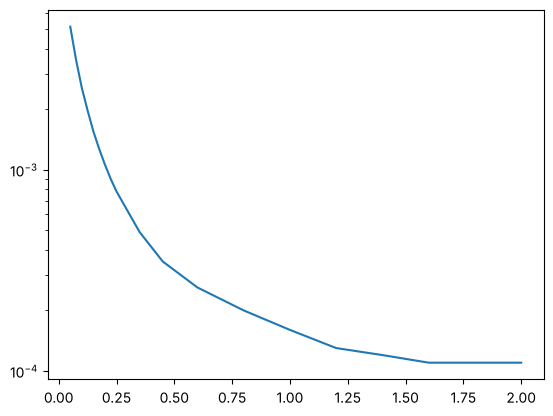

In [19]:
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_yscale('log')